# Market Regime & Risk Analysis

### How do changes in US Treasury yields relate to the behaviour of major financial assets?

## Overview

Financial markets respond to changing expectations around interest rates, inflation and economic growth. This project uses Python to explore the risk, return and cross-asset behaviour of five major financial assets between January 2020 and September 2026, with a particular focus on their relationship with movements in the US 10-Year Treasury yield.

### Assets Analysed

- S&P 500
- Nasdaq-100
- FTSE 100
- Gold futures
- Bitcoin

The US 10-Year Treasury yield is used as the macro-financial variable for the regime analysis.

## Research Questions

This project investigates four main questions:

1. How did the risk and return characteristics of these assets differ over the sample period?
2. How strongly were returns across the asset classes correlated?
3. How severe were their drawdowns during periods of market stress?
4. Did asset returns differ between rising- and falling-yield environments?

To test the final question, yield environments are examined in two ways:

- **Daily yield direction:** whether the US 10-Year Treasury yield increased or decreased on a given day.
- **20-day yield regime:** whether the yield was higher or lower than approximately one trading month earlier.

## Tools

Python | pandas | NumPy | Matplotlib | SciPy | yfinance

In [1]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import ttest_ind

In [2]:
tickers = {
    "S&P 500": "^GSPC",
    "Nasdaq 100": "^NDX",
    "FTSE 100": "^FTSE",
    "Gold": "GC=F",
    "Bitcoin": "BTC-USD",
    "US 10Y Yield": "^TNX"
}

tickers

{'S&P 500': '^GSPC',
 'Nasdaq 100': '^NDX',
 'FTSE 100': '^FTSE',
 'Gold': 'GC=F',
 'Bitcoin': 'BTC-USD',
 'US 10Y Yield': '^TNX'}

## Data & Methodology

Historical market data are retrieved using the `yfinance` Python library for the period from January 2020 to September 2026.

The analysis uses:

- **S&P 500 (`^GSPC`)** – US large-cap equities
- **Nasdaq-100 (`^NDX`)** – US large-cap growth and technology-oriented equities
- **FTSE 100 (`^FTSE`)** – UK large-cap equities
- **Gold Futures (`GC=F`)** – gold futures prices
- **Bitcoin (`BTC-USD`)** – cryptocurrency
- **US 10-Year Treasury Yield (`^TNX`)** – benchmark US government bond yield

Because Bitcoin trades continuously while traditional financial markets do not, the datasets contain different trading calendars. For cross-asset comparisons, observations are aligned to dates for which data are available across all series.

Daily percentage returns are calculated from adjusted prices. Risk is examined using annualised volatility and maximum drawdown, while cross-asset relationships are assessed using return correlations.

Treasury-yield relationships are explored using both daily yield changes and 20-trading-day yield changes. Welch's t-tests are used as an exploratory test of whether mean asset returns differ between rising- and falling-yield groups.

In [3]:
start_date = "2020-01-01"
end_date = "2026-10-01"

data = yf.download(
    list(tickers.values()),
    start=start_date,
    end=end_date,
    auto_adjust=True,
    progress=False
)

data.head()

Price             Close                                                      \
Ticker          BTC-USD         GC=F        ^FTSE        ^GSPC         ^NDX   
Date                                                                          
2020-01-01  7200.174316          NaN          NaN          NaN          NaN   
2020-01-02  6985.470215  1524.500000  7604.299805  3257.850098  8872.219727   
2020-01-03  7344.884277  1549.199951  7622.399902  3234.850098  8793.900391   
2020-01-04  7410.656738          NaN          NaN          NaN          NaN   
2020-01-05  7411.317383          NaN          NaN          NaN          NaN   

Price                     High                                         ...  \
Ticker       ^TNX      BTC-USD         GC=F        ^FTSE        ^GSPC  ...   
Date                                                                   ...   
2020-01-01    NaN  7254.330566          NaN          NaN          NaN  ...   
2020-01-02  1.882  7212.155273  1528.699951  7624.799805  3258.139893  ...   
2020-01-03  1.788  7413.715332  1552.699951  7626.399902  3246.149902  ...   
2020-01-04    NaN  7427.385742          NaN          NaN          NaN  ...   
2020-01-05    NaN  7544.497070          NaN          NaN          NaN  ...   

Price              Open                                        Volume         \
Ticker            ^FTSE        ^GSPC         ^NDX   ^TNX      BTC-USD   GC=F   
Date                                                                           
2020-01-01          NaN          NaN          NaN    NaN  18565664997    NaN   
2020-01-02  7542.399902  3244.669922  8802.219727  1.903  20802083465  214.0   
2020-01-03  7604.299805  3226.360107  8755.169922  1.828  28111481032  107.0   
2020-01-04          NaN          NaN          NaN    NaN  18444271275    NaN   
2020-01-05          NaN          NaN          NaN    NaN  19725074095    NaN   

Price                                                     
Ticker            ^FTSE         ^GSPC          ^NDX ^TNX  
Date                                                      
2020-01-01          NaN           NaN           NaN  NaN  
2020-01-02  482206700.0  3.459930e+09  2.862700e+09  0.0  
2020-01-03  475628900.0  3.484700e+09  2.586520e+09  0.0  
2020-01-04          NaN           NaN           NaN  NaN  
2020-01-05          NaN           NaN           NaN  NaN  

[5 rows x 30 columns]

In [4]:
prices = data["Close"].copy()

prices = prices.rename(columns={
    "^GSPC": "S&P 500",
    "^NDX": "Nasdaq 100",
    "^FTSE": "FTSE 100",
    "GC=F": "Gold",
    "BTC-USD": "Bitcoin",
    "^TNX": "US 10Y Yield"
})

prices.head(10)

Ticker,Bitcoin,Gold,FTSE 100,S&P 500,Nasdaq 100,US 10Y Yield
Date,,,,,,
2020-01-01,7200.174316,NaN,NaN,NaN,NaN,NaN
2020-01-02,6985.470215,1524.500000,7604.299805,3257.850098,8872.219727,1.882
2020-01-03,7344.884277,1549.199951,7622.399902,3234.850098,8793.900391,1.788
2020-01-04,7410.656738,NaN,NaN,NaN,NaN,NaN
2020-01-05,7411.317383,NaN,NaN,NaN,NaN,NaN
2020-01-06,7769.219238,1566.199951,7575.299805,3246.280029,8848.519531,1.811
2020-01-07,8163.692383,1571.800049,7573.899902,3237.179932,8846.450195,1.827
2020-01-08,8079.862793,1557.400024,7574.899902,3253.050049,8912.370117,1.874
2020-01-09,7879.071289,1551.699951,7598.100098,3274.699951,8989.629883,1.858


### Data Quality and Alignment

Before calculating returns, the dataset is checked for missing observations. Different assets follow different trading calendars: Bitcoin trades seven days a week, while equity and futures markets close on weekends and market holidays.

For consistent cross-asset comparisons, the series are aligned to common trading dates and remaining missing observations are checked before proceeding with the analysis.

In [5]:
print("Number of rows:", len(prices))

print("\nMissing values:")
print(prices.isna().sum())

Number of rows: 2465

Missing values:
Ticker
Bitcoin           0
Gold            767
FTSE 100        762
S&P 500         770
Nasdaq 100      770
US 10Y Yield    770
dtype: int64


### Data Quality and Alignment

The downloaded series follow different trading calendars. Bitcoin trades continuously, while equity and futures markets close on weekends and market holidays.

To make cross-asset comparisons consistent, the datasets are aligned to dates for which observations are available across all series. This avoids treating differences in trading calendars as missing market observations.

In [6]:
market_data = prices.dropna()

print("Original rows:", len(prices))
print("Rows after alignment:", len(market_data))

print("\nMissing values after alignment:")
print(market_data.isna().sum())

Original rows: 2465
Rows after alignment: 1661

Missing values after alignment:
Ticker
Bitcoin         0
Gold            0
FTSE 100        0
S&P 500         0
Nasdaq 100      0
US 10Y Yield    0
dtype: int64


### Daily Returns

Daily percentage returns are calculated from consecutive observations for each asset. Returns, rather than price levels, are used for most of the analysis because they allow assets with very different price scales to be compared consistently.

In [7]:
asset_names = ["Bitcoin", "Gold", "FTSE 100", "S&P 500", "Nasdaq 100"]

returns = market_data[asset_names].pct_change().dropna()

returns.head()


Ticker,Bitcoin,Gold,FTSE 100,S&P 500,Nasdaq 100
Date,,,,,
2020-01-03,0.051452,0.016202,0.002380,-0.007060,-0.008827
2020-01-06,0.057773,0.010973,-0.006179,0.003533,0.006211
2020-01-07,0.050774,0.003576,-0.000185,-0.002803,-0.000234
2020-01-08,-0.010269,-0.009161,0.000132,0.004902,0.007452
2020-01-09,-0.024851,-0.003660,0.003063,0.006655,0.008669


In [8]:
returns_percent = returns * 100

returns_percent.head().round(2)

Ticker,Bitcoin,Gold,FTSE 100,S&P 500,Nasdaq 100
Date,,,,,
2020-01-03,5.15,1.62,0.24,-0.71,-0.88
2020-01-06,5.78,1.10,-0.62,0.35,0.62
2020-01-07,5.08,0.36,-0.02,-0.28,-0.02
2020-01-08,-1.03,-0.92,0.01,0.49,0.75
2020-01-09,-2.49,-0.37,0.31,0.67,0.87


## 1. Risk and Return Analysis

The first stage compares the historical performance and risk characteristics of the five assets.

Returns are evaluated using both compound annual growth rate (CAGR) and arithmetic annualised returns. Risk is assessed using annualised volatility and maximum drawdown. A simplified return-to-volatility ratio is also reported to compare returns relative to the level of volatility experienced.

In [9]:
trading_days = 252

annual_return = returns.mean() * trading_days
annual_volatility = returns.std() * np.sqrt(trading_days)

summary_stats = pd.DataFrame({
    "Annualised Return (%)": annual_return * 100,
    "Annualised Volatility (%)": annual_volatility * 100
})

summary_stats.round(2)

,Annualised Return (%),Annualised Volatility (%)
Ticker,,
Bitcoin,56.41,60.68
Gold,17.22,19.34
FTSE 100,6.39,16.31
S&P 500,15.04,20.34
Nasdaq 100,21.93,25.38


In [10]:
sharpe_ratio = annual_return / annual_volatility

summary_stats["Sharpe Ratio"] = sharpe_ratio

summary_stats.round(2)

,Annualised Return (%),Annualised Volatility (%),Sharpe Ratio
Ticker,,,
Bitcoin,56.41,60.68,0.93
Gold,17.22,19.34,0.89
FTSE 100,6.39,16.31,0.39
S&P 500,15.04,20.34,0.74
Nasdaq 100,21.93,25.38,0.86


### Cumulative Performance

To compare long-term performance across assets, daily returns are compounded over time. The series represents the growth of an initial value of 100, making assets with very different price levels directly comparable.

Both standard and logarithmic-scale charts are shown because Bitcoin's substantially larger cumulative growth compresses the movements of the other assets on a conventional linear scale.

In [11]:
cumulative_returns = (
    market_data[asset_names]
    / market_data[asset_names].iloc[0]
) * 100

cumulative_returns.head()

Ticker,Bitcoin,Gold,FTSE 100,S&P 500,Nasdaq 100
Date,,,,,
2020-01-02,100.000000,100.000000,100.000000,100.000000,100.000000
2020-01-03,105.145166,101.620200,100.238025,99.294013,99.117252
2020-01-06,111.219703,102.735320,99.618637,99.644856,99.732872
2020-01-07,116.866755,103.102660,99.600227,99.365527,99.709548
2020-01-08,115.666699,102.158086,99.613378,99.852662,100.452541


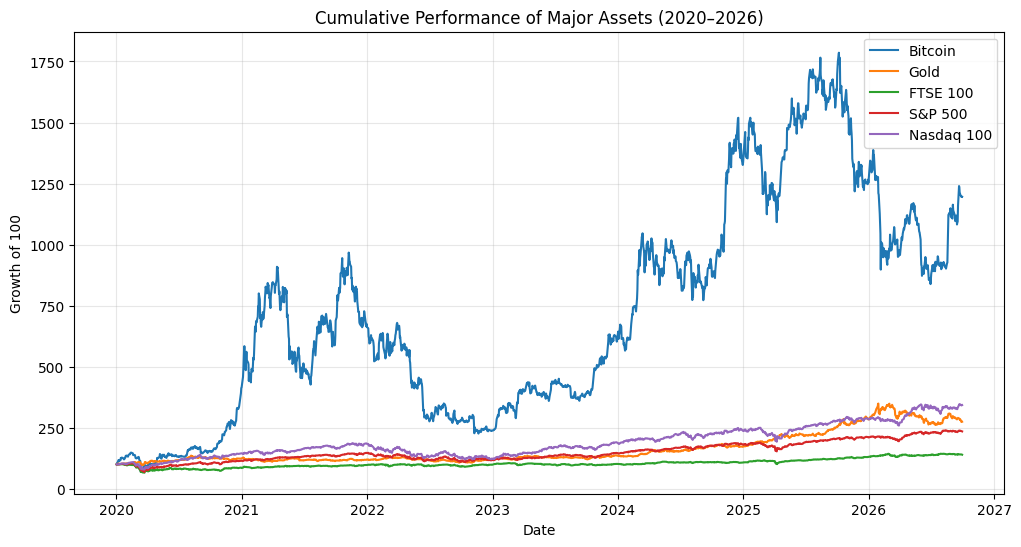

In [12]:
plt.figure(figsize=(12, 6))

for asset in cumulative_returns.columns:
    plt.plot(
        cumulative_returns.index,
        cumulative_returns[asset],
        label=asset
    )

plt.title("Cumulative Performance of Major Assets (2020–2026)")
plt.xlabel("Date")
plt.ylabel("Growth of 100")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

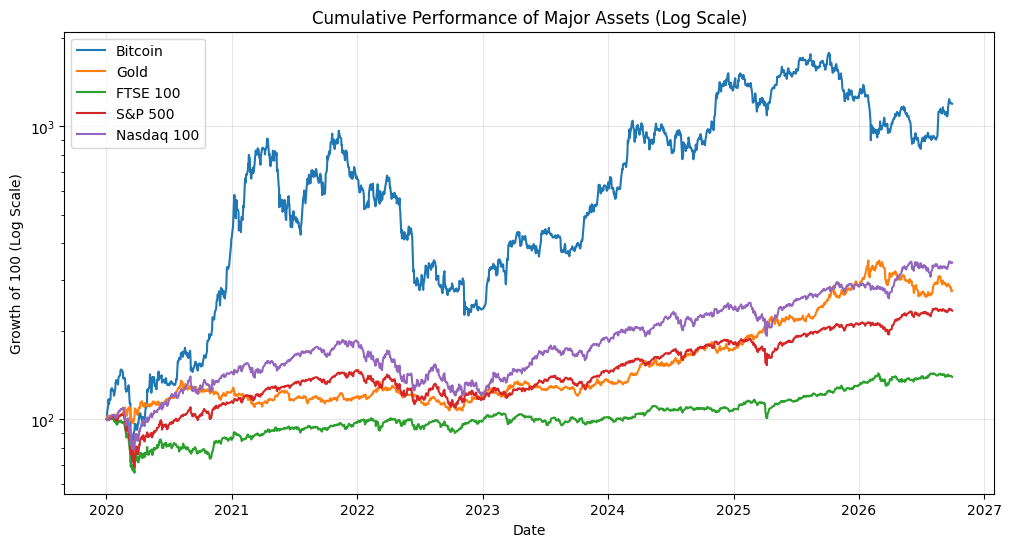

In [13]:
plt.figure(figsize=(12, 6))

for asset in cumulative_returns.columns:
    plt.plot(
        cumulative_returns.index,
        cumulative_returns[asset],
        label=asset
    )

plt.yscale("log")

plt.title("Cumulative Performance of Major Assets (Log Scale)")
plt.xlabel("Date")
plt.ylabel("Growth of 100 (Log Scale)")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

### Interpretation

Bitcoin generated by far the strongest cumulative growth over the sample period, but this performance was accompanied by substantially greater volatility and drawdown risk.

Among the equity indices, the Nasdaq-100 outperformed the S&P 500 and FTSE 100 over the period. Gold also produced substantial cumulative growth while exhibiting lower volatility than Bitcoin and the Nasdaq-100.

The results highlight an important risk-return trade-off: higher historical returns should not be considered independently of the volatility and downside risk required to achieve them.

## 2. Cross-Asset Correlation

Correlation measures how closely the daily returns of different assets moved together during the sample period.

A correlation close to **+1** indicates that two assets tended to move in the same direction, while a value close to **0** indicates a weak linear relationship. Lower correlations can be particularly relevant from a portfolio-diversification perspective.

In [14]:
correlation_matrix = returns.corr()

correlation_matrix.round(2)

Ticker,Bitcoin,Gold,FTSE 100,S&P 500,Nasdaq 100
Ticker,,,,,
Bitcoin,1.00,0.12,0.22,0.37,0.38
Gold,0.12,1.00,0.12,0.12,0.13
FTSE 100,0.22,0.12,1.00,0.50,0.35
S&P 500,0.37,0.12,0.50,1.00,0.93
Nasdaq 100,0.38,0.13,0.35,0.93,1.00


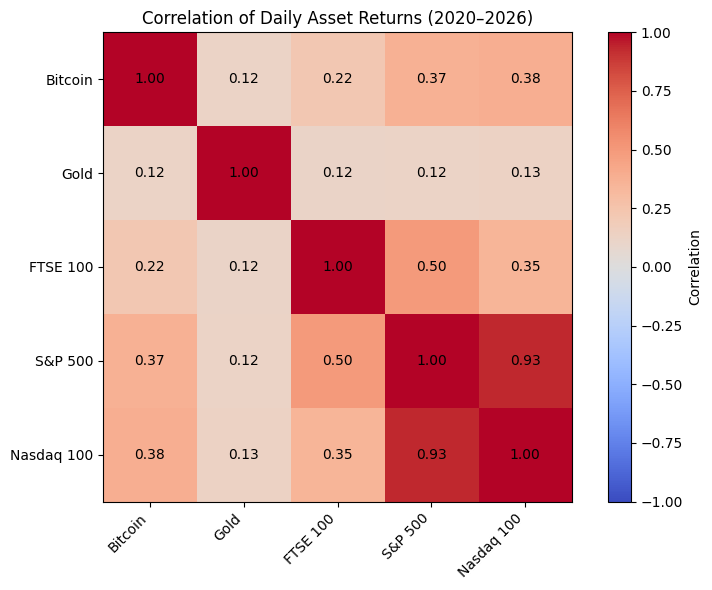

In [15]:
fig, ax = plt.subplots(figsize=(8, 6))

heatmap = ax.imshow(correlation_matrix, cmap="coolwarm", vmin=-1, vmax=1)

ax.set_xticks(range(len(correlation_matrix.columns)))
ax.set_yticks(range(len(correlation_matrix.columns)))

ax.set_xticklabels(correlation_matrix.columns, rotation=45, ha="right")
ax.set_yticklabels(correlation_matrix.columns)

for i in range(len(correlation_matrix.columns)):
    for j in range(len(correlation_matrix.columns)):
        ax.text(
            j,
            i,
            f"{correlation_matrix.iloc[i, j]:.2f}",
            ha="center",
            va="center"
        )

plt.colorbar(heatmap, label="Correlation")
plt.title("Correlation of Daily Asset Returns (2020–2026)")
plt.tight_layout()
plt.show()

### Interpretation

The S&P 500 and Nasdaq-100 had the strongest relationship, with a daily-return correlation of **0.93**. This indicates that the two US equity indices generally moved closely together during the sample period.

The FTSE 100 was moderately correlated with the S&P 500 (**0.50**) but less strongly with the Nasdaq-100 (**0.35**), reflecting differences between the UK and US equity markets.

Gold had particularly low correlations with the equity indices (**0.12–0.13**) and Bitcoin (**0.12**). Within this sample, Gold therefore provided the strongest diversification characteristics among the assets analysed.

Bitcoin had moderate positive correlations with the S&P 500 (**0.37**) and Nasdaq-100 (**0.38**), suggesting that it did not behave as a completely independent asset during the period.

## 3. Volatility and Drawdown Analysis

Average volatility does not show how risk changes through time. To examine changing market conditions, 30-day rolling annualised volatility is calculated for each asset.

Maximum drawdown is also analysed to measure downside risk. Drawdown represents the percentage decline from an asset's previous peak, providing an indication of the losses an investor could have experienced during periods of market stress.

In [16]:
rolling_volatility = returns.rolling(window=30).std() * np.sqrt(252) * 100

rolling_volatility.tail()

Ticker,Bitcoin,Gold,FTSE 100,S&P 500,Nasdaq 100
Date,,,,,
2026-09-24,47.755755,21.778431,8.980609,10.204798,15.570565
2026-09-25,47.796921,21.763857,8.996252,10.286676,15.487961
2026-09-28,47.945447,23.800906,8.864122,10.329776,15.524867
2026-09-29,47.761143,23.780060,8.934965,10.329531,15.526378
2026-09-30,47.658697,23.614142,8.937729,10.250724,15.523253


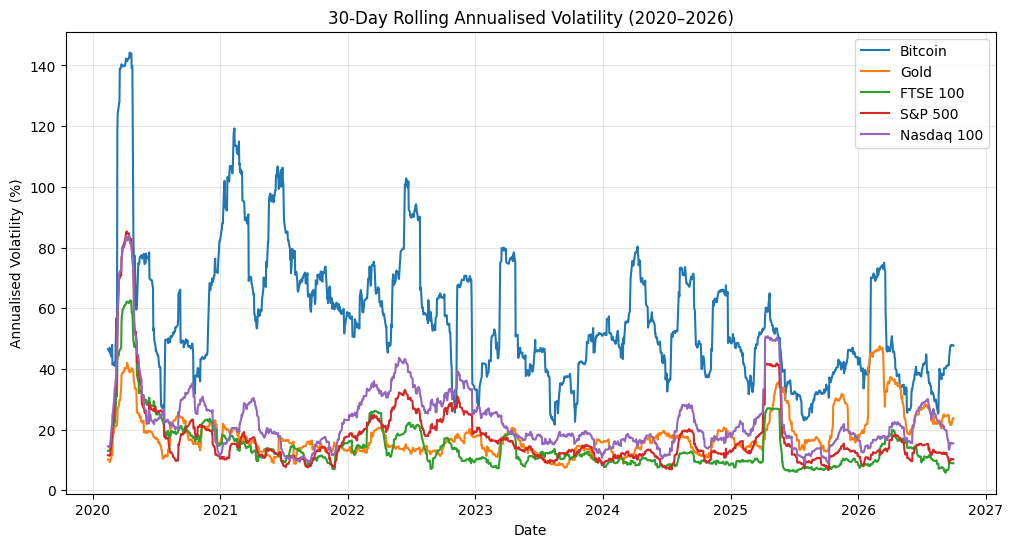

In [17]:
plt.figure(figsize=(12, 6))

for asset in rolling_volatility.columns:
    plt.plot(
        rolling_volatility.index,
        rolling_volatility[asset],
        label=asset
    )

plt.title("30-Day Rolling Annualised Volatility (2020–2026)")
plt.xlabel("Date")
plt.ylabel("Annualised Volatility (%)")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [18]:
running_max = cumulative_returns.cummax()

drawdowns = (cumulative_returns / running_max - 1) * 100

drawdowns.min().round(2)


Ticker
Bitcoin      -76.63
Gold         -24.94
FTSE 100     -34.93
S&P 500      -33.92
Nasdaq 100   -35.56
dtype: float64

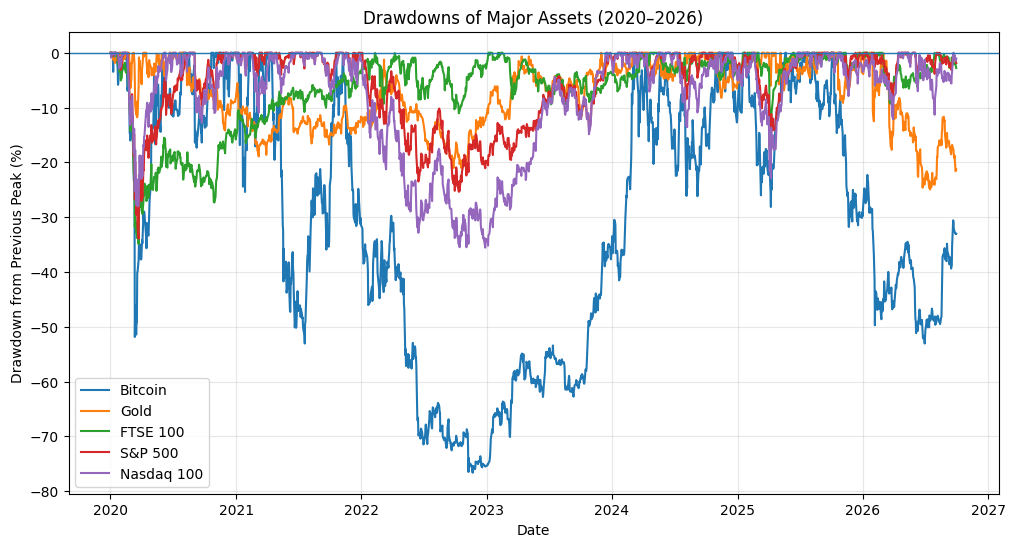

In [19]:
plt.figure(figsize=(12, 6))

for asset in drawdowns.columns:
    plt.plot(
        drawdowns.index,
        drawdowns[asset],
        label=asset
    )

plt.axhline(0, linewidth=1)

plt.title("Drawdowns of Major Assets (2020–2026)")
plt.xlabel("Date")
plt.ylabel("Drawdown from Previous Peak (%)")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

### Interpretation

Risk varied substantially across both assets and time. Bitcoin exhibited the highest overall volatility and experienced the largest maximum drawdown, falling **76.63%** from a previous peak at its worst point in the sample.

The three equity indices experienced maximum drawdowns of approximately **34–36%**, while Gold recorded the smallest maximum drawdown at **24.94%**.

The rolling-volatility analysis also shows that risk is not constant through time. Periods of relatively stable markets were interrupted by substantial volatility spikes, reinforcing the importance of examining changing risk conditions rather than relying only on a single full-period volatility estimate.

Taken together with the return analysis, the results illustrate that the assets generating higher historical returns did not necessarily provide those returns with lower risk.

## 4. Treasury Yield Regime Analysis

The final stage examines whether asset returns differed across changes in the US 10-Year Treasury yield.

Two definitions are used:

1. **Daily yield direction** – each trading day is classified according to whether the 10-year yield rose or fell compared with the previous observation.
2. **20-day yield regime** – each day is classified according to whether the 10-year yield was higher or lower than 20 trading days earlier.

Using both definitions helps test whether the findings are sensitive to how a rising- or falling-yield environment is measured.

Welch's t-test is used to compare mean returns between rising- and falling-yield groups. Effect sizes are also examined for the daily classification to assess the magnitude of the differences relative to normal return variability.

In [20]:
yield_change = market_data["US 10Y Yield"].diff()

yield_data = pd.DataFrame({
    "Yield": market_data["US 10Y Yield"],
    "Daily Change": yield_change
})

yield_data.head(10)

,Yield,Daily Change
Date,,
2020-01-02,1.882,NaN
2020-01-03,1.788,-0.094
2020-01-06,1.811,0.023
2020-01-07,1.827,0.016
2020-01-08,1.874,0.047
2020-01-09,1.858,-0.016
2020-01-10,1.825,-0.033
2020-01-13,1.848,0.023
2020-01-14,1.818,-0.030


In [21]:
yield_regime = pd.Series(
    np.where(yield_change > 0, "Rising Yield",
             np.where(yield_change < 0, "Falling Yield", "Unchanged")),
    index=market_data.index
)

yield_regime.value_counts()


Rising Yield     846
Falling Yield    792
Unchanged         23
Name: count, dtype: int64

In [22]:
regime_returns = returns.copy()

regime_returns["Yield Regime"] = yield_regime

regime_performance = (
    regime_returns
    .groupby("Yield Regime")[asset_names]
    .mean() * 100
)

regime_performance.round(3)

Ticker,Bitcoin,Gold,FTSE 100,S&P 500,Nasdaq 100
Yield Regime,,,,,
Falling Yield,0.156,0.315,-0.091,0.013,0.077
Rising Yield,0.278,-0.170,0.129,0.095,0.084
Unchanged,0.568,0.346,0.235,0.394,0.599


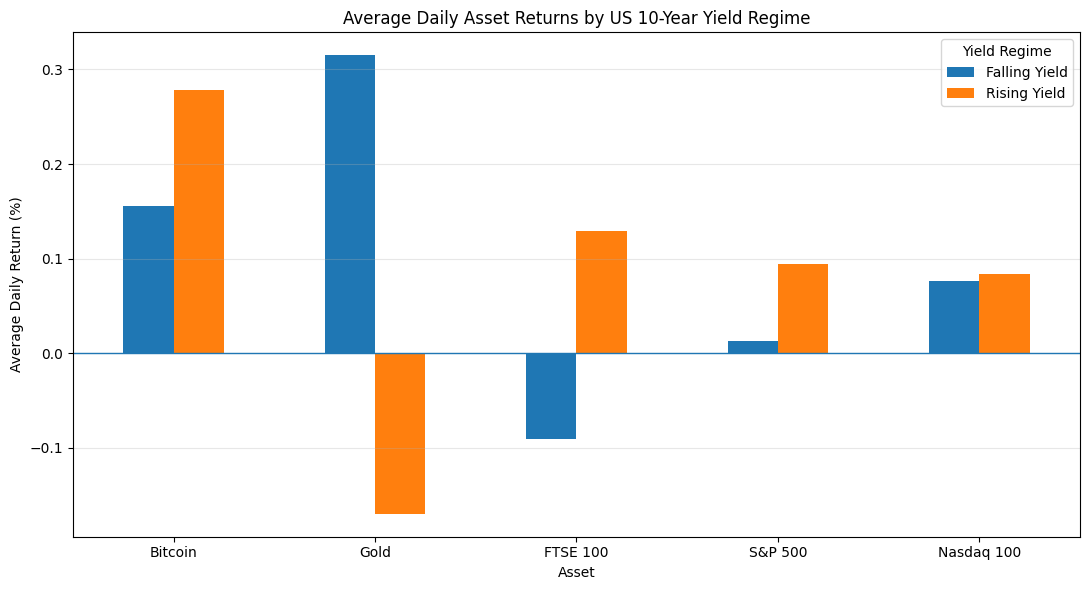

In [23]:
regime_comparison = regime_performance.loc[
    ["Falling Yield", "Rising Yield"]
].T

regime_comparison.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.axhline(0, linewidth=1)

plt.title("Average Daily Asset Returns by US 10-Year Yield Regime")
plt.xlabel("Asset")
plt.ylabel("Average Daily Return (%)")
plt.xticks(rotation=0)
plt.legend(title="Yield Regime")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


### Interpretation: Daily Yield Movements

Asset behaviour differed considerably between rising- and falling-yield days.

Gold showed the clearest negative relationship with daily yield movements, averaging **0.315%** on falling-yield days compared with **-0.170%** on rising-yield days. The difference was statistically significant using Welch's t-test (**p < 0.001**) and produced the largest absolute effect size among the assets analysed (**Cohen's d = -0.406**).

The FTSE 100 displayed the opposite pattern, averaging **0.129%** on rising-yield days compared with **-0.091%** on falling-yield days. This difference was also statistically significant (**p < 0.001**), although its effect size was smaller (**Cohen's d = 0.214**).

Bitcoin, the S&P 500 and Nasdaq-100 did not show statistically significant differences between the two groups at the 5% level.

These results describe associations within the sample and should not be interpreted as evidence that changes in Treasury yields caused the observed asset returns.

In [24]:
test_results = []

for asset in asset_names:
    rising = regime_returns.loc[
        regime_returns["Yield Regime"] == "Rising Yield", asset
    ].dropna()

    falling = regime_returns.loc[
        regime_returns["Yield Regime"] == "Falling Yield", asset
    ].dropna()

    t_stat, p_value = ttest_ind(
        rising,
        falling,
        equal_var=False
    )

    test_results.append({
        "Asset": asset,
        "T-statistic": t_stat,
        "P-value": p_value
    })

test_results_df = pd.DataFrame(test_results).set_index("Asset")

test_results_df.round(4)

,T-statistic,P-value
Asset,,
Bitcoin,0.6467,0.5179
Gold,-8.2336,0.0000
FTSE 100,4.3357,0.0000
S&P 500,1.2790,0.2011
Nasdaq 100,0.0879,0.9300


In [25]:
mean_difference = (
    regime_performance.loc["Rising Yield"]
    - regime_performance.loc["Falling Yield"]
)

effect_summary = pd.DataFrame({
    "Falling Yield Return (%)":
        regime_performance.loc["Falling Yield"],
    "Rising Yield Return (%)":
        regime_performance.loc["Rising Yield"],
    "Difference (pp)":
        mean_difference,
    "P-value":
        test_results_df["P-value"]
})

effect_summary.round(3)


,Falling Yield Return (%),Rising Yield Return (%),Difference (pp),P-value
Bitcoin,0.156,0.278,0.122,0.518
Gold,0.315,-0.170,-0.485,0.000
FTSE 100,-0.091,0.129,0.220,0.000
S&P 500,0.013,0.095,0.081,0.201
Nasdaq 100,0.077,0.084,0.007,0.930


In [26]:
effect_sizes = []

for asset in asset_names:
    rising = regime_returns.loc[
        regime_returns["Yield Regime"] == "Rising Yield", asset
    ].dropna()

    falling = regime_returns.loc[
        regime_returns["Yield Regime"] == "Falling Yield", asset
    ].dropna()

    pooled_std = np.sqrt(
        ((len(rising) - 1) * rising.var() +
         (len(falling) - 1) * falling.var())
        /
        (len(rising) + len(falling) - 2)
    )

    cohens_d = (rising.mean() - falling.mean()) / pooled_std

    effect_sizes.append({
        "Asset": asset,
        "Cohen's d": cohens_d
    })

effect_sizes_df = pd.DataFrame(effect_sizes).set_index("Asset")

effect_sizes_df.round(3)

,Cohen's d
Asset,
Bitcoin,0.032
Gold,-0.406
FTSE 100,0.214
S&P 500,0.063
Nasdaq 100,0.004


In [27]:
yield_20d_change = market_data["US 10Y Yield"].diff(20)

yield_regime_20d = pd.Series(
    np.where(
        yield_20d_change > 0,
        "Rising Yield Regime",
        np.where(
            yield_20d_change < 0,
            "Falling Yield Regime",
            "Unchanged"
        )
    ),
    index=market_data.index
)

yield_regime_20d.value_counts()

Rising Yield Regime     933
Falling Yield Regime    708
Unchanged                20
Name: count, dtype: int64

In [28]:
regime_20d_returns = returns.copy()

regime_20d_returns["Yield Regime"] = yield_regime_20d

regime_20d_performance = (
    regime_20d_returns
    .groupby("Yield Regime")[asset_names]
    .mean() * 100
)

regime_20d_performance.round(3)

Ticker,Bitcoin,Gold,FTSE 100,S&P 500,Nasdaq 100
Yield Regime,,,,,
Falling Yield Regime,0.297,0.124,-0.002,0.077,0.140
Rising Yield Regime,0.138,0.023,0.050,0.047,0.046
Unchanged,1.689,0.202,-0.153,0.043,0.158


In [29]:
test_results_20d = []

for asset in asset_names:
    rising = regime_20d_returns.loc[
        regime_20d_returns["Yield Regime"] == "Rising Yield Regime",
        asset
    ].dropna()

    falling = regime_20d_returns.loc[
        regime_20d_returns["Yield Regime"] == "Falling Yield Regime",
        asset
    ].dropna()

    t_stat, p_value = ttest_ind(
        rising,
        falling,
        equal_var=False
    )

    test_results_20d.append({
        "Asset": asset,
        "T-statistic": t_stat,
        "P-value": p_value
    })

test_results_20d_df = (
    pd.DataFrame(test_results_20d)
    .set_index("Asset")
)

test_results_20d_df.round(4)

,T-statistic,P-value
Asset,,
Bitcoin,-0.8277,0.4080
Gold,-1.6682,0.0955
FTSE 100,0.9768,0.3288
S&P 500,-0.4661,0.6412
Nasdaq 100,-1.1586,0.2468


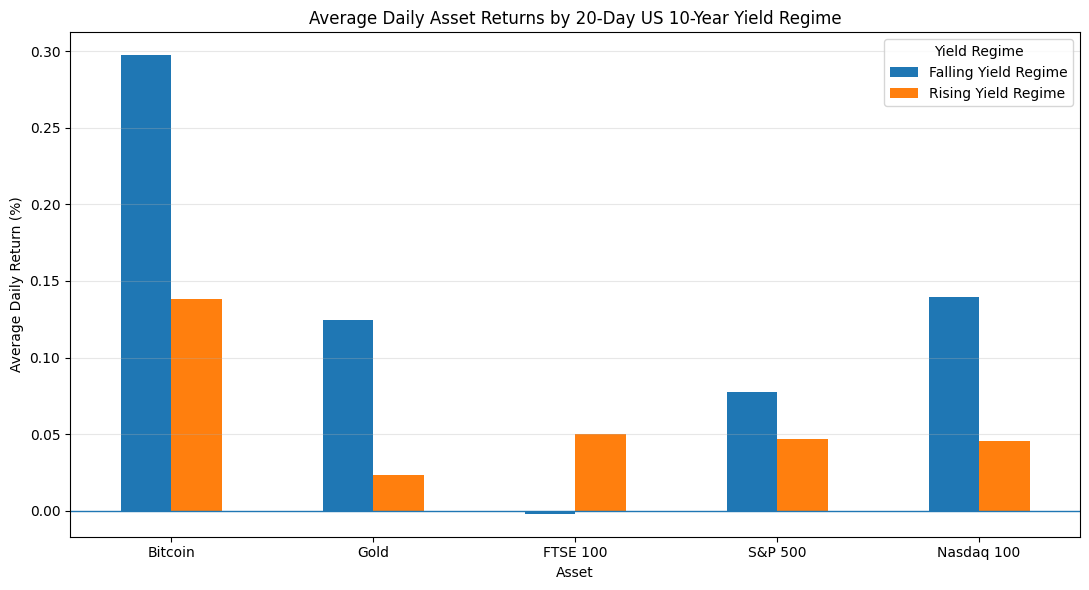

In [30]:
regime_20d_comparison = regime_20d_performance.loc[
    ["Falling Yield Regime", "Rising Yield Regime"]
].T

regime_20d_comparison.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.axhline(0, linewidth=1)

plt.title("Average Daily Asset Returns by 20-Day US 10-Year Yield Regime")
plt.xlabel("Asset")
plt.ylabel("Average Daily Return (%)")
plt.xticks(rotation=0)
plt.legend(title="Yield Regime")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

### Interpretation: 20-Day Yield Regimes

The results change when the yield environment is defined using the 20-trading-day change rather than daily movements.

Bitcoin, Gold, the S&P 500 and Nasdaq-100 all recorded higher average daily returns during falling-yield regimes, while the FTSE 100 performed slightly better during rising-yield regimes. However, Welch's t-tests found that **none of these differences were statistically significant at the 5% level**.

Gold came closest to conventional statistical significance (**p = 0.0955**), while the remaining p-values were substantially above 0.05.

This contrasts with the daily analysis, where Gold and the FTSE 100 showed statistically significant differences. The comparison therefore suggests that the apparent relationship between Treasury yields and asset returns is **sensitive to the time horizon used to define the yield environment**.

Because consecutive 20-day changes contain overlapping observations, these statistical results should be treated as exploratory rather than definitive.c

In [31]:
years = (cumulative_returns.index[-1] - cumulative_returns.index[0]).days / 365.25

cagr = (
    (cumulative_returns.iloc[-1] / 100) ** (1 / years) - 1
) * 100

performance_summary = summary_stats.copy()

performance_summary["CAGR (%)"] = cagr
performance_summary["Maximum Drawdown (%)"] = drawdowns.min()

performance_summary[
    [
        "CAGR (%)",
        "Annualised Return (%)",
        "Annualised Volatility (%)",
        "Sharpe Ratio",
        "Maximum Drawdown (%)"
    ]
].round(2)

,CAGR (%),Annualised Return (%),Annualised Volatility (%),Sharpe Ratio,Maximum Drawdown (%)
Ticker,,,,,
Bitcoin,44.49,56.41,60.68,0.93,-76.63
Gold,16.16,17.22,19.34,0.89,-24.94
FTSE 100,5.06,6.39,16.31,0.39,-34.93
S&P 500,13.50,15.04,20.34,0.74,-33.92
Nasdaq 100,20.04,21.93,25.38,0.86,-35.56


In [32]:
performance_summary = performance_summary.rename(
    columns={
        "Annualised Return (%)": "Arithmetic Annualised Return (%)",
        "Sharpe Ratio": "Return-to-Volatility Ratio"
    }
)

performance_summary = performance_summary[
    [
        "CAGR (%)",
        "Arithmetic Annualised Return (%)",
        "Annualised Volatility (%)",
        "Return-to-Volatility Ratio",
        "Maximum Drawdown (%)"
    ]
]

performance_summary.round(2)

,CAGR (%),Arithmetic Annualised Return (%),Annualised Volatility (%),Return-to-Volatility Ratio,Maximum Drawdown (%)
Ticker,,,,,
Bitcoin,44.49,56.41,60.68,0.93,-76.63
Gold,16.16,17.22,19.34,0.89,-24.94
FTSE 100,5.06,6.39,16.31,0.39,-34.93
S&P 500,13.50,15.04,20.34,0.74,-33.92
Nasdaq 100,20.04,21.93,25.38,0.86,-35.56


## Limitations

Several limitations should be considered when interpreting the results:

- **Association rather than causation:** Differences in asset returns across yield environments do not demonstrate that changes in Treasury yields caused those returns. Asset prices and bond yields can respond simultaneously to factors such as inflation data, monetary-policy expectations and economic news.

- **Regime definition:** Classifying yield environments using daily or 20-trading-day changes is a simplified approach. Different time horizons or regime-classification methods could produce different results.

- **Overlapping observations:** The 20-day regime measure uses rolling changes, meaning consecutive observations share much of the same underlying information. The associated statistical tests should therefore be interpreted as exploratory rather than definitive.

- **Trading calendars:** Bitcoin trades continuously, while equity and futures markets have different trading days and holidays. Cross-asset analysis is therefore restricted to dates with observations available across all series.

- **Sample period:** The analysis covers January 2020 to September 2026, a period containing several unusual market environments. Results should not automatically be assumed to hold in other periods.

- **Market proxies:** The analysis uses market indices and gold futures as proxies for broad asset-class behaviour and does not account for transaction costs, taxes or investability.

## Key Findings

- **Bitcoin delivered the highest growth but also the greatest risk.** It achieved a CAGR of 44.51% over the sample period, alongside annualised volatility of 60.68% and a maximum drawdown of -76.63%.

- **Gold provided the strongest diversification characteristics.** Its daily returns had correlations of only 0.12–0.13 with the major equity indices, while its maximum drawdown (-24.94%) was the smallest among the assets analysed.

- **US equities moved closely together.** The S&P 500 and Nasdaq-100 had a daily-return correlation of 0.93, although the Nasdaq-100 generated higher growth and experienced greater volatility.

- **Daily Treasury-yield movements were associated with significantly different returns for Gold and the FTSE 100.** Gold performed better on falling-yield days, while the FTSE 100 performed better on rising-yield days. The differences were statistically significant using Welch's t-tests (p < 0.001).

- **The relationship was sensitive to the definition of the yield environment.** When yield regimes were instead defined using the direction of the 20-trading-day change in the US 10-Year Treasury yield, none of the five assets showed a statistically significant difference in average returns at the 5% level.

### Overall Takeaway

The analysis suggests that relationships between Treasury yields and asset returns are more nuanced than a simple "higher yields = lower asset prices" narrative. Results vary across asset classes and depend on how the yield environment is defined. These findings should be interpreted as associations rather than evidence of causality.